Clase 013 · `013_numpy` · Primer contacto con NumPy, la capa numérica debajo de pandas y
matplotlib. Una lista y un arreglo frente a los mismos operadores, `shape` y `ndim` como
preguntas de cabecera, `reshape` para cambiar de forma sin cambiar los números, rebanadas en dos
dimensiones, `arange` y `linspace` para construir ejes, y `mgrid` y `meshgrid` para construir
mallas. Termina con el ejemplo de superficie 3D de la galería de matplotlib. No lee datos
externos; `numpy` se instala con `uv add numpy`.

## Librerías

`numpy` se importa con el alias `np`, que ya es apellido. `pandas` y `matplotlib` acompañan;
matplotlib sólo se usa en la figura del final.

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Una lista no es un arreglo

`lista + lista` con listas de Python concatena: el resultado tiene ocho elementos. Nada de
aritmética.

In [2]:
lista = [1,2,3,4]
lista + lista 

[1, 2, 3, 4, 1, 2, 3, 4]

`np.array` convierte la lista en un `ndarray`, el tipo central de NumPy.

In [3]:
arreglo = np.array(lista)
type(arreglo)

numpy.ndarray

Con arreglos, `+` suma elemento por elemento. Mismo operador, otro significado.

In [5]:
arreglo + arreglo

array([2, 4, 6, 8])

`**` eleva cada elemento al cuadrado.

In [6]:
arreglo**2

array([ 1,  4,  9, 16])

Ojo con `^`: no es potencia, es el *o exclusivo* bit a bit (XOR). `arreglo ^ 2` da
`[3, 0, 1, 6]`, que no tiene nada que ver con elevar al cuadrado. En Python la potencia siempre
es `**`.

In [7]:
arreglo^2 ##Operador logico

array([3, 0, 1, 6])

La división también es elemento por elemento y devuelve flotantes (`1.`), aunque los enteros
se dividan exactos.

In [8]:
arreglo/arreglo

array([1., 1., 1., 1.])

## `shape` y `ndim`

`shape` es una tupla con el tamaño de cada eje. `(4,)` significa un solo eje de cuatro
elementos: un vector.

In [9]:
arreglo.shape

(4,)

`ndim` es el número de ejes: 1.

In [12]:
arreglo.ndim

1

## Una matriz: lista de listas

Una lista de dos listas de tres números se convierte en un arreglo de dos renglones y tres
columnas.

In [14]:
mn = np.array([ 
    [1,2,3],
    [4,5,6]
  ])
mn

array([[1, 2, 3],
       [4, 5, 6]])

`shape` ahora tiene dos números: `(2, 3)`, renglones y columnas, en ese orden.

In [15]:
mn.shape

(2, 3)

`ndim` es 2.

In [17]:
mn.ndim

2

## Las formas tienen que ser compatibles

Sumar la matriz `(2, 3)` con el vector `(4,)` falla: NumPy no encuentra cómo alinearlos. El
error dice *could not be broadcast together* y es el mensaje que hay que aprender a leer:
siempre menciona las dos formas en conflicto.

In [20]:
mn + arreglo

ValueError: operands could not be broadcast together with shapes (2,3) (4,) 

Dos matrices de la misma forma se suman sin problema, elemento por elemento.

In [19]:
mn + mn

array([[ 2,  4,  6],
       [ 8, 10, 12]])

## `ndmin`: el mismo vector con dos ejes

`ndmin=2` obliga al arreglo a tener al menos dos dimensiones: `m2` es una matriz de un renglón
y tres columnas, `(1, 3)`, mientras que `m` es el vector plano de siempre.

In [27]:
m2 = np.array([1, 2, 3], ndmin=2)
m = np.array([1,2,3])
m2.shape

(1, 3)

`m2.ndim` es 2 aunque tenga los mismos tres números.

In [25]:
m2.ndim

2

Impreso, `m2` lleva dos pares de corchetes: es una matriz.

In [26]:
m2

array([[1, 2, 3]])

`m` lleva uno: es un vector.

In [28]:
m

array([1, 2, 3])

`m2` de nuevo, para tenerlos juntos.

In [29]:
m2

array([[1, 2, 3]])

`shape` lo resume: `(1, 3)` contra `(3,)`. Para NumPy son objetos distintos aunque contengan
los mismos números; de eso depende que una operación entre ellos funcione o no.

In [30]:
m2.shape, m.shape

((1, 3), (3,))

## `reshape`: los mismos números, otra forma

Una matriz de tres renglones y cuatro columnas: doce números.

In [31]:
n = np.array([
    [1,2,3,4],
    [5,6,7,8],
    [9,10,11,12]
])

`ndim` 2 y `shape` `(3, 4)`.

In [33]:
n.ndim,n.shape

(2, (3, 4))

`reshape((6, 2))` reacomoda los doce números en seis renglones de dos. Los recorre en orden,
renglón por renglón; no se pierde ni se repite ninguno.

In [34]:
n.reshape((6,2))

array([[ 1,  2],
       [ 3,  4],
       [ 5,  6],
       [ 7,  8],
       [ 9, 10],
       [11, 12]])

`reshape(12, 1)`: doce renglones de una columna. Una matriz columna.

In [35]:
n.reshape(12,1)

array([[ 1],
       [ 2],
       [ 3],
       [ 4],
       [ 5],
       [ 6],
       [ 7],
       [ 8],
       [ 9],
       [10],
       [11],
       [12]])

## Un arreglo tiene que ser rectangular

Una lista de listas con renglones de distinta longitud (3, 4 y 4) no es una matriz. NumPy la
rechaza: *inhomogeneous shape*. Es el precio de la homogeneidad que hace rápidos a los
arreglos.

In [36]:
np.array([
    [1,2,3],
    [4,5,6,7],
    [8,9,10,11]
])

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (3,) + inhomogeneous part.

Repaso de `m`: una dimensión…

In [37]:
m.ndim

1

…y forma `(3,)`.

In [38]:
m.shape

(3,)

`n` sigue intacto: `reshape` devuelve un arreglo nuevo, no modifica el original.

In [39]:
n

array([[ 1,  2,  3,  4],
       [ 5,  6,  7,  8],
       [ 9, 10, 11, 12]])

`reshape(12, 1)`, igual que arriba.

In [40]:
n.reshape(12,1)

array([[ 1],
       [ 2],
       [ 3],
       [ 4],
       [ 5],
       [ 6],
       [ 7],
       [ 8],
       [ 9],
       [10],
       [11],
       [12]])

`reshape(12)` lo aplana: un vector de doce. Sin el `1`, el resultado tiene un solo eje.

In [41]:
n.reshape(12)

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12])

## El `-1` de `reshape`

`-1` en un eje le pide a NumPy que calcule ese tamaño: `reshape(3, -1)` con doce números da
`(3, 4)`.

In [45]:
n.reshape(3,-1)

array([[ 1,  2,  3,  4],
       [ 5,  6,  7,  8],
       [ 9, 10, 11, 12]])

`reshape(-1, 4)` llega a la misma forma por el otro lado.

In [47]:
n.reshape(-1,4)

array([[ 1,  2,  3,  4],
       [ 5,  6,  7,  8],
       [ 9, 10, 11, 12]])

Doce números no caben en cinco renglones iguales: `reshape(5, -1)` falla porque 12 no es
divisible entre 5. El `-1` ayuda, pero no inventa.

In [48]:
n.reshape(5,-1)

ValueError: cannot reshape array of size 12 into shape (5,newaxis)

## `arange` y `reshape` para construir matrices

Escribir a mano una matriz de 3 por 10 es largo y propenso a errores.

In [49]:
matriz = [
    [1,2,3,4,5,6,7,8,9,10],
    [11,12,13,14,15,16,17,18,19,20],
    [21,22,23,24,25,26,27,28,29,30]
]
np.array(matriz)

array([[ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10],
       [11, 12, 13, 14, 15, 16, 17, 18, 19, 20],
       [21, 22, 23, 24, 25, 26, 27, 28, 29, 30]])

`np.arange(1, 31)` genera los enteros del 1 al 30 (el extremo final no entra, como en `range`)
y `reshape(3, 10)` les da la forma. Mismo resultado, una línea.

In [55]:
np.arange(1,31).reshape(3,10)

array([[ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10],
       [11, 12, 13, 14, 15, 16, 17, 18, 19, 20],
       [21, 22, 23, 24, 25, 26, 27, 28, 29, 30]])

Lo mismo en dos pasos, guardando el rango y la matriz en variables para usarlas abajo.

In [54]:
rango = np.arange(1,31)
matriz = rango.reshape(3,10)
matriz

array([[ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10],
       [11, 12, 13, 14, 15, 16, 17, 18, 19, 20],
       [21, 22, 23, 24, 25, 26, 27, 28, 29, 30]])

## Rebanadas en dos dimensiones

Dentro de los corchetes va una rebanada por eje, separadas por coma. `matriz[::, ::2]` toma
todos los renglones y las columnas de dos en dos: la primera, la tercera, la quinta…

In [60]:
matriz[::,::2] ##slicing 

array([[ 1,  3,  5,  7,  9],
       [11, 13, 15, 17, 19],
       [21, 23, 25, 27, 29]])

`matriz[1:2:1, ::]`: sólo el renglón 1 (el segundo), con todas sus columnas. Como se pidió con
una rebanada y no con un entero, el resultado conserva dos dimensiones, `(1, 10)`.

In [67]:
matriz[1:2:1,::]

array([[11, 12, 13, 14, 15, 16, 17, 18, 19, 20]])

## `linspace`: puntos equiespaciados

`np.linspace(0, 1)` devuelve 50 puntos entre 0 y 1, ambos extremos incluidos. Es el eje `x` que
matplotlib estaba esperando.

In [68]:
np.linspace(0,1)

array([0.        , 0.02040816, 0.04081633, 0.06122449, 0.08163265,
       0.10204082, 0.12244898, 0.14285714, 0.16326531, 0.18367347,
       0.20408163, 0.2244898 , 0.24489796, 0.26530612, 0.28571429,
       0.30612245, 0.32653061, 0.34693878, 0.36734694, 0.3877551 ,
       0.40816327, 0.42857143, 0.44897959, 0.46938776, 0.48979592,
       0.51020408, 0.53061224, 0.55102041, 0.57142857, 0.59183673,
       0.6122449 , 0.63265306, 0.65306122, 0.67346939, 0.69387755,
       0.71428571, 0.73469388, 0.75510204, 0.7755102 , 0.79591837,
       0.81632653, 0.83673469, 0.85714286, 0.87755102, 0.89795918,
       0.91836735, 0.93877551, 0.95918367, 0.97959184, 1.        ])

El tercer argumento es cuántos puntos: 1000.

In [70]:
np.linspace(0,1,1000)

array([0.        , 0.001001  , 0.002002  , 0.003003  , 0.004004  ,
       0.00500501, 0.00600601, 0.00700701, 0.00800801, 0.00900901,
       0.01001001, 0.01101101, 0.01201201, 0.01301301, 0.01401401,
       0.01501502, 0.01601602, 0.01701702, 0.01801802, 0.01901902,
       0.02002002, 0.02102102, 0.02202202, 0.02302302, 0.02402402,
       0.02502503, 0.02602603, 0.02702703, 0.02802803, 0.02902903,
       0.03003003, 0.03103103, 0.03203203, 0.03303303, 0.03403403,
       0.03503504, 0.03603604, 0.03703704, 0.03803804, 0.03903904,
       0.04004004, 0.04104104, 0.04204204, 0.04304304, 0.04404404,
       0.04504505, 0.04604605, 0.04704705, 0.04804805, 0.04904905,
       0.05005005, 0.05105105, 0.05205205, 0.05305305, 0.05405405,
       0.05505506, 0.05605606, 0.05705706, 0.05805806, 0.05905906,
       0.06006006, 0.06106106, 0.06206206, 0.06306306, 0.06406406,
       0.06506507, 0.06606607, 0.06706707, 0.06806807, 0.06906907,
       0.07007007, 0.07107107, 0.07207207, 0.07307307, 0.07407

Con 10 puntos el paso es 1/9, por eso aparecen 0.111, 0.222, …: `linspace` fija el número de
puntos, no el paso.

In [71]:
np.linspace(0,1,10)

array([0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
       0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ])

`arange` hace lo contrario: fija el paso (0.1) y el extremo final no entra. Diez valores, de
0.0 a 0.9.

In [72]:
np.arange(0,1,0.1)

array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])

## Mallas con `mgrid`

`np.mgrid[0:5, 0:10]` devuelve dos matrices de `(5, 10)`: una con el índice del renglón
repetido a lo largo y otra con el índice de la columna repetido hacia abajo. Así cada punto de
la malla tiene su coordenada en cada eje.

In [75]:
X, Y = np.mgrid[0:5,0:10]

`X`: cada renglón lleva su número.

In [76]:
X

array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
       [2, 2, 2, 2, 2, 2, 2, 2, 2, 2],
       [3, 3, 3, 3, 3, 3, 3, 3, 3, 3],
       [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]])

`Y`: cada columna lleva el suyo.

In [77]:
Y

array([[0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
       [0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
       [0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
       [0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
       [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]])

## Mallas con `meshgrid`

Primero dos ejes con `linspace`: diez puntos de 0 a 1 en `X` y diez de -1 a 1 en `Y`.

In [78]:
X = np.linspace(0,1,10)
Y = np.linspace(-1,1,10)
X,Y

(array([0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
        0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ]),
 array([-1.        , -0.77777778, -0.55555556, -0.33333333, -0.11111111,
         0.11111111,  0.33333333,  0.55555556,  0.77777778,  1.        ]))

`np.meshgrid(X, Y)` cruza los dos ejes y devuelve las matrices de coordenadas, como `mgrid`
pero a partir de ejes arbitrarios.

In [84]:
np.meshgrid(X,Y)

(array([[0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
         0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ],
        [0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
         0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ],
        [0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
         0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ],
        [0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
         0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ],
        [0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
         0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ],
        [0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
         0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ],
        [0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
         0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ],
        [0.        , 0.1111

Las guardamos en `XX` y `YY`.

In [80]:
XX, YY = np.meshgrid(X,Y)

`XX`: el eje `X` repetido en cada renglón, una matriz de `(10, 10)`.

In [81]:
XX

array([[0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
        0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ],
       [0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
        0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ],
       [0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
        0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ],
       [0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
        0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ],
       [0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
        0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ],
       [0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
        0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ],
       [0.        , 0.11111111, 0.22222222, 0.33333333, 0.44444444,
        0.55555556, 0.66666667, 0.77777778, 0.88888889, 1.        ],
       [0.        , 0.11111111, 0.2222222

## Una superficie evaluada sobre la malla

El ejemplo de malla de alambre 3D de la galería de matplotlib (`plot_wireframe`), tal como
viene en la documentación. Lo que importa aquí es el patrón: `arange` construye dos ejes,
`meshgrid` los cruza en `X` y `Y`, y la función se evalúa sobre las dos matrices de un solo
golpe (`Z = np.sin(np.sqrt(X**2 + Y**2))`), sin un solo ciclo. El resto del código dibuja dos
veces la misma superficie para mostrar `axlim_clip`, un argumento de matplotlib 3.10 que
recorta los segmentos que se salen de los límites de los ejes.

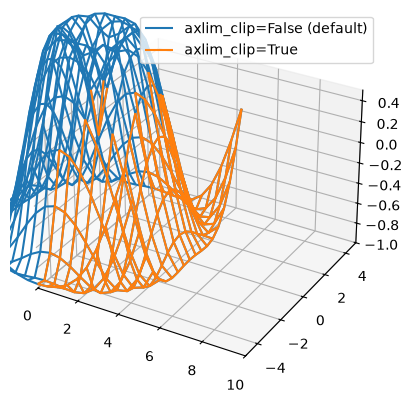

In [86]:
#| label: fig-numpy-wireframe
#| fig-cap: "Superficie `sin(sqrt(x² + y²))` evaluada sobre una malla de `meshgrid` y dibujada con `plot_wireframe`. En azul la superficie completa; en naranja la misma con `axlim_clip=True`, que oculta lo que sale de los límites de los ejes."
#| fig-alt: "Malla de alambre tridimensional con forma de cráter; la versión azul se desborda por la izquierda y la naranja queda recortada dentro de la caja de ejes."
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})

# Make the data
x = np.arange(-5, 5, 0.5)
y = np.arange(-5, 5, 0.5)
X, Y = np.meshgrid(x, y)
R = np.sqrt(X**2 + Y**2)
Z = np.sin(R)

# Default behavior is axlim_clip=False
ax.plot_wireframe(X, Y, Z, color='C0')

# When axlim_clip=True, note that when a line segment has one vertex outside
# the view limits, the entire line is hidden. The same is true for 3D patches
# if one of their vertices is outside the limits (not shown).
ax.plot_wireframe(X, Y, Z, color='C1', axlim_clip=True)

# In this example, data where x < 0 or z > 0.5 is clipped
ax.set(xlim=(0, 10), ylim=(-5, 5), zlim=(-1, 0.5))
ax.legend(['axlim_clip=False (default)', 'axlim_clip=True'])

plt.show()

Las matrices que dejó el ejemplo: `X`, con los valores de -5 a 4.5 repetidos en cada renglón…

In [87]:
X

array([[-5. , -4.5, -4. , -3.5, -3. , -2.5, -2. , -1.5, -1. , -0.5,  0. ,
         0.5,  1. ,  1.5,  2. ,  2.5,  3. ,  3.5,  4. ,  4.5],
       [-5. , -4.5, -4. , -3.5, -3. , -2.5, -2. , -1.5, -1. , -0.5,  0. ,
         0.5,  1. ,  1.5,  2. ,  2.5,  3. ,  3.5,  4. ,  4.5],
       [-5. , -4.5, -4. , -3.5, -3. , -2.5, -2. , -1.5, -1. , -0.5,  0. ,
         0.5,  1. ,  1.5,  2. ,  2.5,  3. ,  3.5,  4. ,  4.5],
       [-5. , -4.5, -4. , -3.5, -3. , -2.5, -2. , -1.5, -1. , -0.5,  0. ,
         0.5,  1. ,  1.5,  2. ,  2.5,  3. ,  3.5,  4. ,  4.5],
       [-5. , -4.5, -4. , -3.5, -3. , -2.5, -2. , -1.5, -1. , -0.5,  0. ,
         0.5,  1. ,  1.5,  2. ,  2.5,  3. ,  3.5,  4. ,  4.5],
       [-5. , -4.5, -4. , -3.5, -3. , -2.5, -2. , -1.5, -1. , -0.5,  0. ,
         0.5,  1. ,  1.5,  2. ,  2.5,  3. ,  3.5,  4. ,  4.5],
       [-5. , -4.5, -4. , -3.5, -3. , -2.5, -2. , -1.5, -1. , -0.5,  0. ,
         0.5,  1. ,  1.5,  2. ,  2.5,  3. ,  3.5,  4. ,  4.5],
       [-5. , -4.5, -4. , -3.5, -3. , -2.

…`Y`, con los mismos valores repetidos en cada columna…

In [88]:
Y

array([[-5. , -5. , -5. , -5. , -5. , -5. , -5. , -5. , -5. , -5. , -5. ,
        -5. , -5. , -5. , -5. , -5. , -5. , -5. , -5. , -5. ],
       [-4.5, -4.5, -4.5, -4.5, -4.5, -4.5, -4.5, -4.5, -4.5, -4.5, -4.5,
        -4.5, -4.5, -4.5, -4.5, -4.5, -4.5, -4.5, -4.5, -4.5],
       [-4. , -4. , -4. , -4. , -4. , -4. , -4. , -4. , -4. , -4. , -4. ,
        -4. , -4. , -4. , -4. , -4. , -4. , -4. , -4. , -4. ],
       [-3.5, -3.5, -3.5, -3.5, -3.5, -3.5, -3.5, -3.5, -3.5, -3.5, -3.5,
        -3.5, -3.5, -3.5, -3.5, -3.5, -3.5, -3.5, -3.5, -3.5],
       [-3. , -3. , -3. , -3. , -3. , -3. , -3. , -3. , -3. , -3. , -3. ,
        -3. , -3. , -3. , -3. , -3. , -3. , -3. , -3. , -3. ],
       [-2.5, -2.5, -2.5, -2.5, -2.5, -2.5, -2.5, -2.5, -2.5, -2.5, -2.5,
        -2.5, -2.5, -2.5, -2.5, -2.5, -2.5, -2.5, -2.5, -2.5],
       [-2. , -2. , -2. , -2. , -2. , -2. , -2. , -2. , -2. , -2. , -2. ,
        -2. , -2. , -2. , -2. , -2. , -2. , -2. , -2. , -2. ],
       [-1.5, -1.5, -1.5, -1.5, -1.5, -1.

…y `Z`, la función evaluada en cada punto.

In [89]:
Z

array([[ 0.70886129,  0.42921793,  0.11965158, -0.17893857, -0.43697552,
        -0.63885987, -0.7820949 , -0.87383376, -0.92618484, -0.95155293,
        -0.95892427, -0.95155293, -0.92618484, -0.87383376, -0.7820949 ,
        -0.63885987, -0.43697552, -0.17893857,  0.11965158,  0.42921793],
       [ 0.42921793,  0.08068791, -0.25938757, -0.54995318, -0.76745273,
        -0.9066904 , -0.97760364, -0.99951869, -0.99473952, -0.98299205,
        -0.97753012, -0.98299205, -0.99473952, -0.99951869, -0.97760364,
        -0.9066904 , -0.76745273, -0.54995318, -0.25938757,  0.08068791],
       [ 0.11965158, -0.25938757, -0.58617619, -0.82381719, -0.95892427,
        -0.99998941, -0.9712778 , -0.90458671, -0.83133918, -0.77677976,
        -0.7568025 , -0.77677976, -0.83133918, -0.90458671, -0.9712778 ,
        -0.99998941, -0.95892427, -0.82381719, -0.58617619, -0.25938757],
       [-0.17893857, -0.54995318, -0.82381719, -0.97196248, -0.99473952,
        -0.9166313 , -0.77677976, -0.61807681, -

Las tres tienen la misma forma, `(20, 20)`: a cada punto de la malla le corresponde una
coordenada `x`, una `y` y un valor `z`.

In [90]:
X.shape,Y.shape,Z.shape

((20, 20), (20, 20), (20, 20))